**INFORMASI DATASET**


Dataset ini menyajikan gambaran mengenai pola aktivitas dan keterlibatan customer gym dalam periode 7 hari terakhir, sehingga sangat ideal untuk eksplorasi customer retention risk dan identifikasi pola kehadiran. Dataset ini mencakup 10.000 sampel data customer sintetis, yang mencakup berbagai atribut aktivitas latihan, penggunaan paket, dan interaksi dengan admin.

Setiap entri memberikan wawasan terhadap perilaku customer, memungkinkan analisis untuk strategi retensi customer dan pengembangan model clustering serta klasifikasi risiko.

**Fitur Utama**


* customer_id                 : ID unik, format CUST00001 dst.
* package_total_sessions      : total sesi dalam paket (pilihan: 8, 12, 16, 24).
* package_duration_days       : masa berlaku paket (8→30, 12→45, 16→60, 24→90 hari).
* days_since_package_purchase : jumlah hari sejak paket dibeli (0 = dibeli hari ini).
* total_sessions_attended     : total sesi yang sudah dihadiri sejak paket dibeli.
* has_ever_visited            : 1 jika pernah hadir minimal 1 kali pada paket ini, 0 jika belum.
* attendance_frequency_7d     : jumlah sesi yang dihadiri dalam 7 hari terakhir.
* missed_session_count_7d     : jumlah sesi terjadwal yang tidak dihadiri (no-show) dalam 7 hari
                                  terakhir. Sesi yang berhasil di-reschedule TIDAK dihitung missed.
* reschedule_frequency_7d     : jumlah permintaan reschedule dalam 7 hari terakhir.
* remaining_package_sessions  : sisa sesi paket yang belum digunakan.
* days_until_package_expiry   : sisa hari sebelum paket kedaluwarsa.
* days_since_last_visit       : jumlah hari sejak kunjungan terakhir.
* reminder_count_7d           : jumlah reminder dari admin dalam 7 hari terakhir.
* reminder_response_count_7d  : jumlah reminder yang direspons customer dalam 7 hari terakhir.



**IMPORT LIBRARY**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
import joblib

**MEMUAT DATASET**

In [ ]:
df = pd.read_csv('synthetic_customer_retention.csv')
df.head()

,customer_id,package_total_sessions,package_duration_days,days_since_package_purchase,total_sessions_attended,has_ever_visited,attendance_frequency_7d,missed_session_count_7d,reschedule_frequency_7d,remaining_package_sessions,days_until_package_expiry,days_since_last_visit,reminder_count_7d,reminder_response_count_7d
0,CUST00001,12,45,15,2,1,0,0,0,10,30,11,0,0
1,CUST00002,24,90,78,21,1,3,0,3,3,12,3,0,0
2,CUST00003,16,60,2,0,0,0,0,0,16,58,2,1,1
3,CUST00004,16,60,40,6,1,0,3,1,10,20,8,5,2
4,CUST00005,8,30,7,1,1,0,1,2,7,23,7,1,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   customer_id                  12000 non-null  object
 1   package_total_sessions       12000 non-null  int64 
 2   package_duration_days        12000 non-null  int64 
 3   days_since_package_purchase  12000 non-null  int64 
 4   total_sessions_attended      12000 non-null  int64 
 5   has_ever_visited             12000 non-null  int64 
 6   attendance_frequency_7d      12000 non-null  int64 
 7   missed_session_count_7d      12000 non-null  int64 
 8   reschedule_frequency_7d      12000 non-null  int64 
 9   remaining_package_sessions   12000 non-null  int64 
 10  days_until_package_expiry    12000 non-null  int64 
 11  days_since_last_visit        12000 non-null  int64 
 12  reminder_count_7d            12000 non-null  int64 
 13  reminder_response_count_7d   12

In [ ]:
df.describe(include="all")

,customer_id,package_total_sessions,package_duration_days,days_since_package_purchase,total_sessions_attended,has_ever_visited,attendance_frequency_7d,missed_session_count_7d,reschedule_frequency_7d,remaining_package_sessions,days_until_package_expiry,days_since_last_visit,reminder_count_7d,reminder_response_count_7d
count,12000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000
unique,12000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,CUST00001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,14.757667,55.341250,28.742500,5.192333,0.931083,1.355333,0.783583,0.778333,9.565333,26.598750,7.507167,1.073750,0.434500
std,NaN,5.386065,20.197742,18.178657,4.514500,0.253323,1.532134,1.112288,0.948915,5.472193,17.769113,9.781330,1.216183,0.730585
min,NaN,8.000000,30.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,12.000000,45.000000,15.000000,2.000000,1.000000,0.000000,0.000000,0.000000,6.000000,13.000000,1.000000,0.000000,0.000000
50%,NaN,12.000000,45.000000,26.000000,4.000000,1.000000,1.000000,0.000000,1.000000,9.000000,23.000000,4.000000,1.000000,0.000000
75%,NaN,16.000000,60.000000,39.000000,7.000000,1.000000,2.000000,1.000000,1.000000,13.000000,36.000000,10.000000,2.000000,1.000000


In [ ]:
numerical_cols = df.select_dtypes(include=['number']).columns

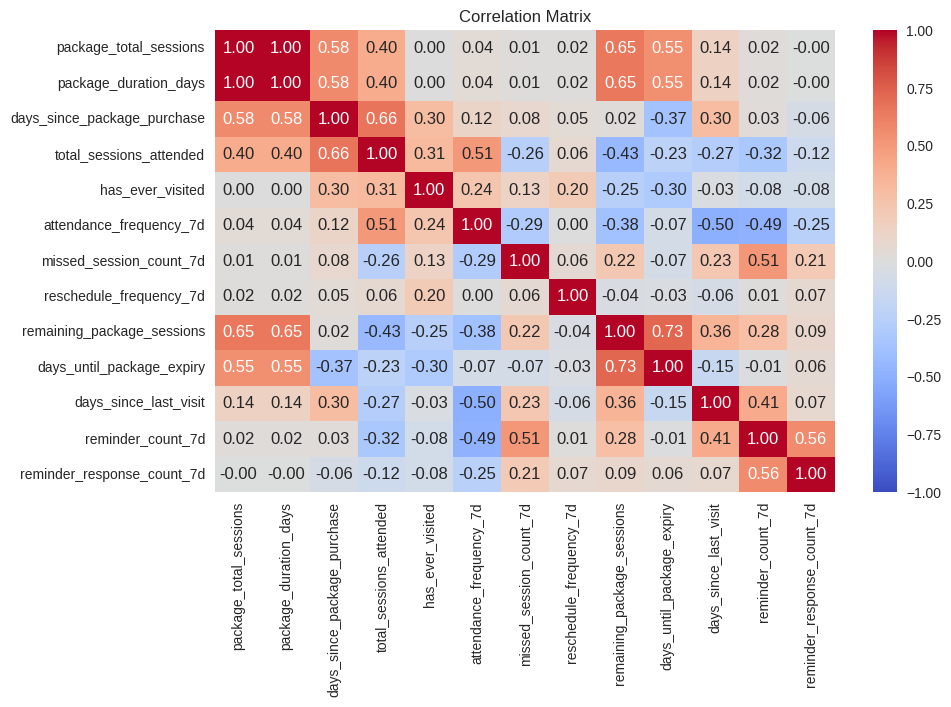

In [ ]:
# Hitung matriks korelasi
correlation = df[numerical_cols].corr()

# Buat visualisasi heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
               annot=True,
               cmap='coolwarm',
               fmt=".2f",
               vmin=-1,
               vmax=1)
plt.title('Correlation Matrix')
plt.show()

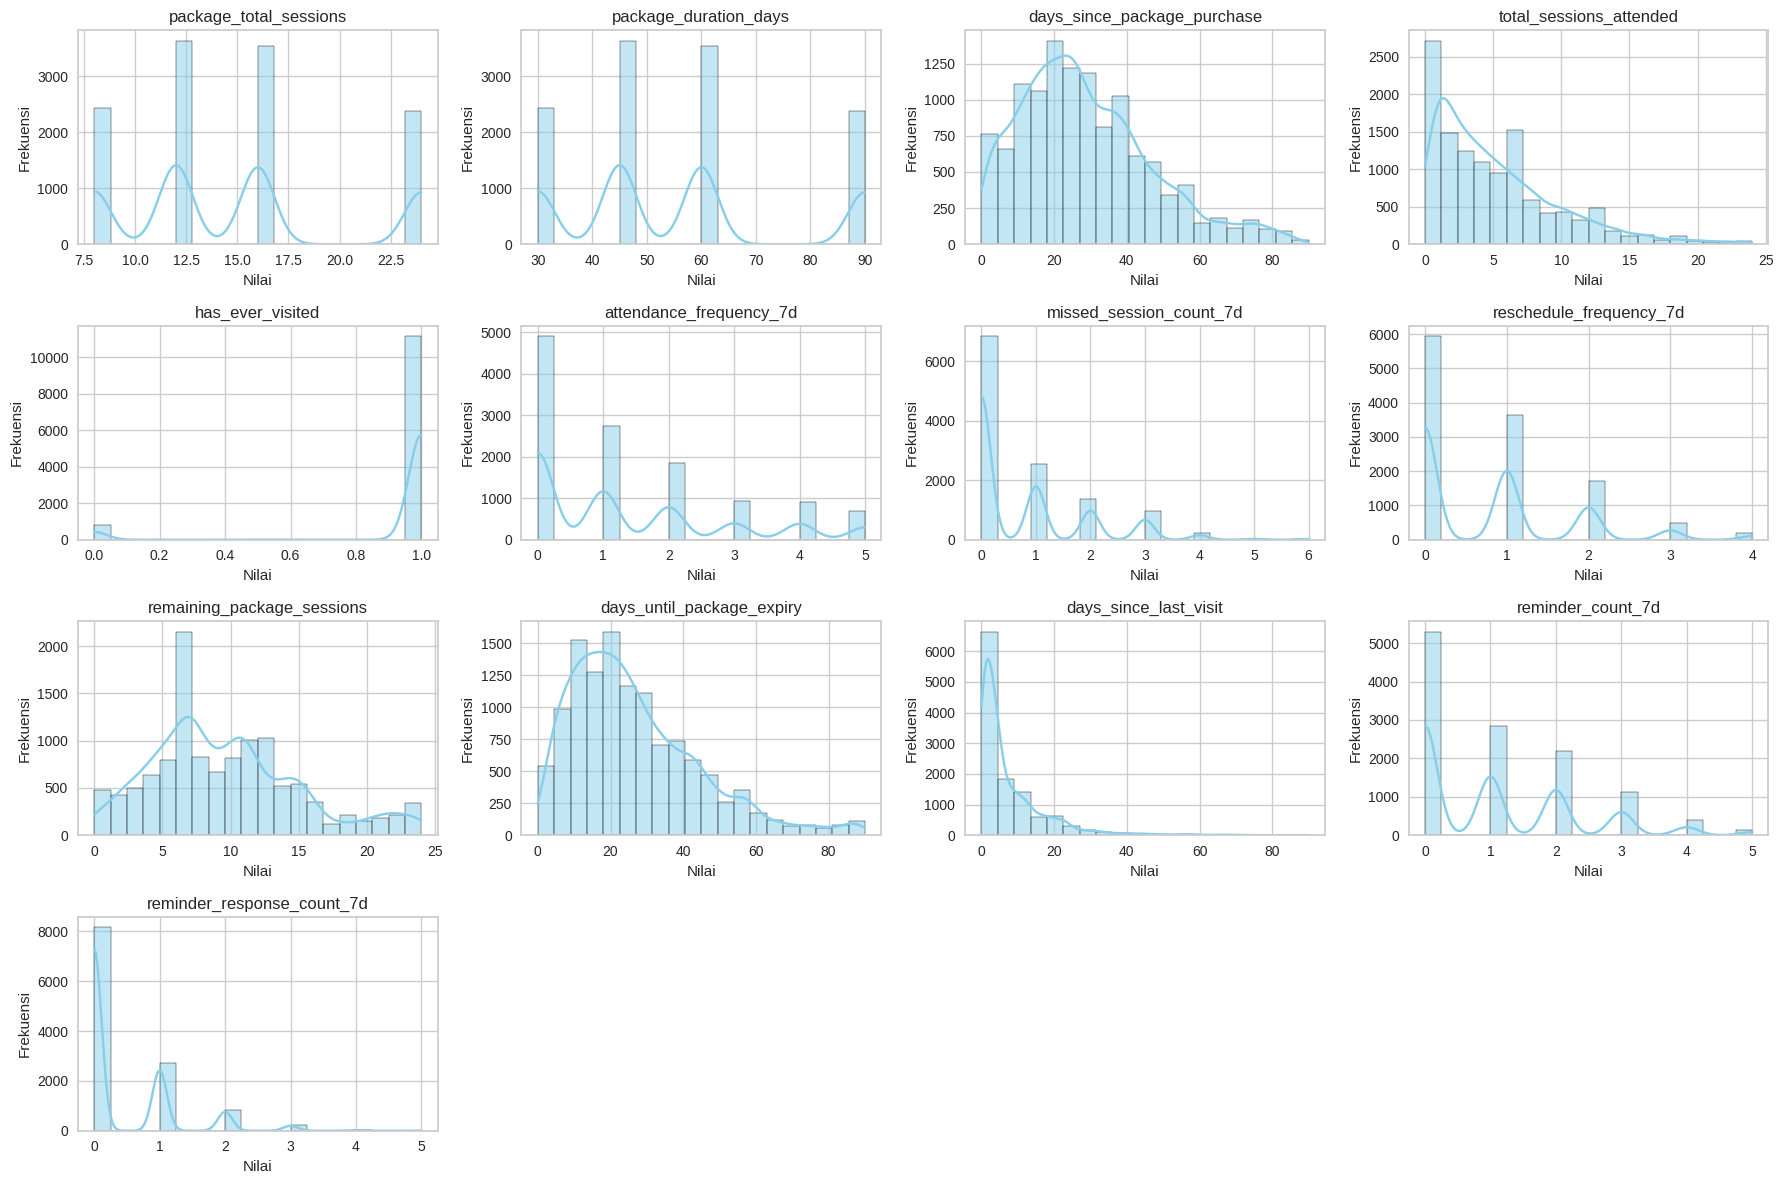

In [ ]:
# Menampilkan histogram untuk semua kolom numerik

# Mengubah grid menjadi 4x4 (total 16 kapasitas) karena kita memiliki 13 kolom numerik
fig, axes = plt.subplots(4, 4, figsize=(18, 12))
axes = axes.flatten()

for i, column in enumerate(numerical_cols):

    ### MULAI CODE ###

    # Tampilkan histogram dan pastikan plot ditempatkan di subplot (axes) yang benar
    sns.histplot(df[column], bins=20, kde=True, color='skyblue', ax=axes[i])

    # Atur judul dan label
    axes[i].set_title(column)
    axes[i].set_xlabel("Nilai")
    axes[i].set_ylabel("Frekuensi")

    ### SELESAI CODE ###

# Menyembunyikan subplot terakhir yang tidak terpakai (karena hanya ada 8 kolom, sedangkan grid ada 9)
for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

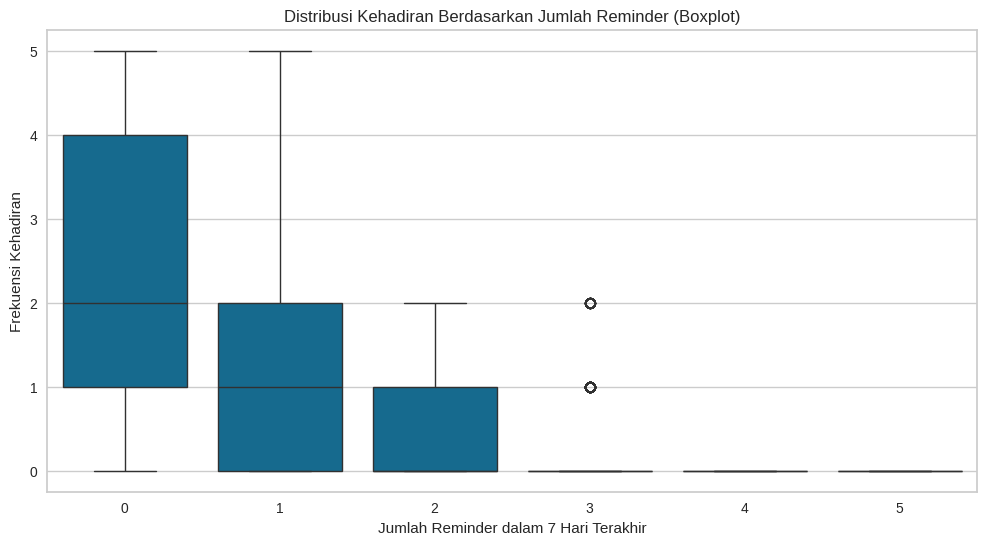

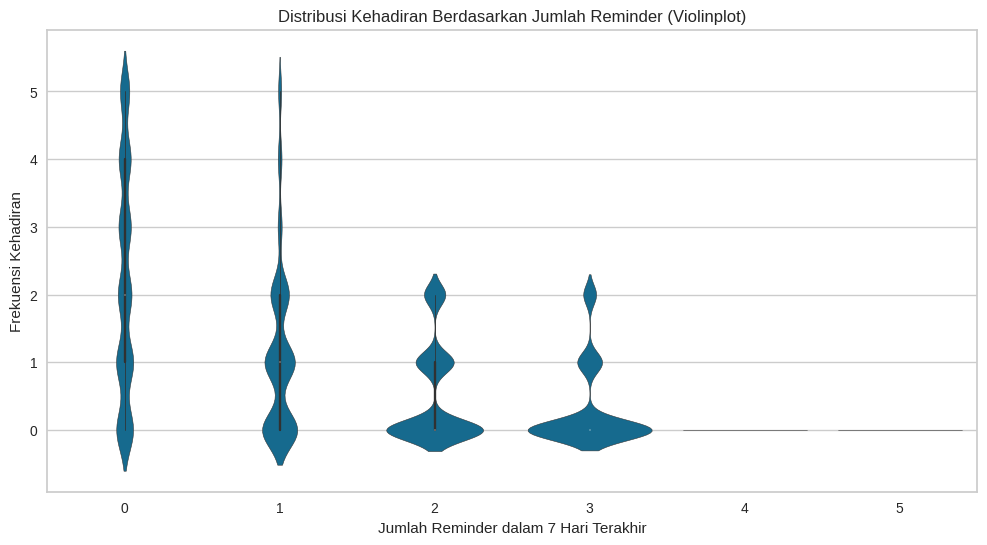

In [ ]:
# Visualisasi yang lebih informatif (Menggunakan kolom yang ada di GymnasiumDataset.csv)

### MULAI CODE ###

plt.figure(figsize=(12, 6))

# Menggunakan kolom yang benar-benar ada di dataset aktif
# x: reminder_count_7d (Kategori jumlah reminder)
# y: attendance_frequency_7d (Frekuensi kehadiran)
sns.boxplot(x='reminder_count_7d', y='attendance_frequency_7d', data=df)

plt.title("Distribusi Kehadiran Berdasarkan Jumlah Reminder (Boxplot)")
plt.xlabel("Jumlah Reminder dalam 7 Hari Terakhir")
plt.ylabel("Frekuensi Kehadiran")

plt.show()

### SELESAI CODE ###

# -----------------------------------------------------------------
# (TANTANGAN OPSIONAL)
# -----------------------------------------------------------------
### MULAI CODE ###

plt.figure(figsize=(12, 6))

# Menggunakan violinplot dengan kolom yang sama untuk melihat kepadatan distribusi
sns.violinplot(x='reminder_count_7d', y='attendance_frequency_7d', data=df)

plt.title("Distribusi Kehadiran Berdasarkan Jumlah Reminder (Violinplot)")
plt.xlabel("Jumlah Reminder dalam 7 Hari Terakhir")
plt.ylabel("Frekuensi Kehadiran")

plt.show()

**Pembersihan dan Pra Pemrosesan Data**

In [ ]:
# Mengecek dataset menggunakan isnull().sum()

### MULAI CODE ###

df.isnull().sum()

### SELESAI CODE ###

,0
customer_id,0
package_total_sessions,0
package_duration_days,0
days_since_package_purchase,0
total_sessions_attended,0
has_ever_visited,0
attendance_frequency_7d,0
missed_session_count_7d,0
reschedule_frequency_7d,0
remaining_package_sessions,0


In [ ]:
# Mengecek dataset menggunakan duplicated().sum()

### MULAI CODE ###

df.duplicated().sum()

### SELESAI CODE ###

np.int64(0)

In [ ]:
# Menangani data yang hilang.

### MULAI CODE ###

# Panggil fungsi untuk menghapus baris yang hilang dan pastikan agar perubahan disimpan kembali ke 'df'
df.dropna(inplace=True)

# Cek kembali dataset menggunakan isnull().sum()
df.isnull().sum()

### SELESAI CODE ###

,0
customer_id,0
package_total_sessions,0
package_duration_days,0
days_since_package_purchase,0
total_sessions_attended,0
has_ever_visited,0
attendance_frequency_7d,0
missed_session_count_7d,0
reschedule_frequency_7d,0
remaining_package_sessions,0


In [ ]:
# Menghapus data duplikat.

### MULAI CODE ###

# Panggil fungsi untuk menghapus baris duplikat dan pastikan agar perubahan disimpan kembali ke 'df'
df.drop_duplicates(inplace=True)

# Cek kembali dataset menggunakan duplicated().sum()
df.duplicated().sum()

### SELESAI CODE ###

np.int64(0)

In [ ]:
cols_to_drop = [col for col in df.columns if 'id' in col.lower()]

# Gunakan fungsi .drop() untuk menghapus kolom-kolom yang ada di 'cols_to_drop'.
df = df.drop(columns=cols_to_drop)

# Tampilkan 5 baris pertama untuk memverifikasi
df.head()

### SELESAI CODE ###

,package_total_sessions,package_duration_days,days_since_package_purchase,total_sessions_attended,has_ever_visited,attendance_frequency_7d,missed_session_count_7d,reschedule_frequency_7d,remaining_package_sessions,days_until_package_expiry,days_since_last_visit,reminder_count_7d,reminder_response_count_7d
0,12,45,15,2,1,0,0,0,10,30,11,0,0
1,24,90,78,21,1,3,0,3,3,12,3,0,0
2,16,60,2,0,0,0,0,0,16,58,2,1,1
3,16,60,40,6,1,0,3,1,10,20,8,5,2
4,8,30,7,1,1,0,1,2,7,23,7,1,0


In [ ]:

df.columns.tolist()


['package_total_sessions',
 'package_duration_days',
 'days_since_package_purchase',
 'total_sessions_attended',
 'has_ever_visited',
 'attendance_frequency_7d',
 'missed_session_count_7d',
 'reschedule_frequency_7d',
 'remaining_package_sessions',
 'days_until_package_expiry',
 'days_since_last_visit',
 'reminder_count_7d',
 'reminder_response_count_7d']

In [ ]:
# Melakukan Handling Outlier Data menggunakan metode drop.

for col in numerical_cols:

    ### MULAI CODE ###

    # Hitung Kuartil 1 (Q1) dan Kuartil 3 (Q3)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Hitung Interquartile Range (IQR)
    IQR = Q3 - Q1

    # Tentukan batas bawah (lower bound) dan batas atas (upper bound)
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Filter DataFrame: Simpan hanya baris di mana nilai 'df[col]' berada DI ANTARA (inklusif) batas bawah dan batas atas.
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

    ### SELESAI CODE ###

# Tampilkan statistik deskriptif setelah outlier dihapus
df.describe()

,package_total_sessions,package_duration_days,days_since_package_purchase,total_sessions_attended,has_ever_visited,attendance_frequency_7d,missed_session_count_7d,reschedule_frequency_7d,remaining_package_sessions,days_until_package_expiry,days_since_last_visit,reminder_count_7d,reminder_response_count_7d
count,6229.000000,6229.000000,6229.000000,6229.000000,6229.0,6229.000000,6229.000000,6229.000000,6229.000000,6229.000000,6229.000000,6229.000000,6229.000000
mean,12.211912,45.794670,23.519666,4.951035,1.0,1.715845,0.403114,0.674105,7.260877,22.275004,4.936587,0.598812,0.303098
std,3.087471,11.578017,11.532763,3.105976,0.0,1.558382,0.639472,0.735864,3.602813,12.168758,5.168080,0.761176,0.552299
min,8.000000,30.000000,0.000000,1.000000,1.0,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,8.000000,30.000000,15.000000,2.000000,1.0,0.000000,0.000000,0.000000,5.000000,13.000000,1.000000,0.000000,0.000000
50%,12.000000,45.000000,23.000000,5.000000,1.0,1.000000,0.000000,1.000000,7.000000,21.000000,3.000000,0.000000,0.000000
75%,16.000000,60.000000,32.000000,7.000000,1.0,3.000000,1.000000,1.000000,10.000000,30.000000,7.000000,1.000000,1.000000
max,16.000000,60.000000,59.000000,12.000000,1.0,5.000000,2.000000,2.000000,15.000000,57.000000,23.000000,2.000000,2.000000


In [ ]:
# Melakukan feature scaling menggunakan StandardScaler() untuk fitur numerik.
# Pastikan kamu menggunakan function head setelah melalukan scaling.

### MULAI CODE ###

# Buat (instantiate) StandardScaler
scaler = StandardScaler()

# Terapkan (fit) scaler ke data dan sekaligus ubah (transform) data tersebut
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# Tampilkan 5 baris pertama untuk memverifikasi hasil scaling
df.head()

### SELESAI CODE ###

,package_total_sessions,package_duration_days,days_since_package_purchase,total_sessions_attended,has_ever_visited,attendance_frequency_7d,missed_session_count_7d,reschedule_frequency_7d,remaining_package_sessions,days_until_package_expiry,days_since_last_visit,reminder_count_7d,reminder_response_count_7d
0,-0.068642,-0.068642,-0.738795,-0.950192,0.0,-1.101131,-0.630437,-0.916147,0.760335,0.634873,1.173337,-0.786757,-0.548839
4,-1.364304,-1.364304,-1.432527,-1.272177,0.0,-1.101131,0.933479,1.801966,-0.072415,0.059583,0.399293,0.527106,-0.548839
5,-1.364304,-1.364304,-1.259094,-1.272177,0.0,-1.101131,-0.630437,-0.916147,-0.072415,-0.104785,0.786315,-0.786757,-0.548839
6,-1.364304,-1.364304,-1.259094,-0.950192,0.0,0.182354,-0.630437,0.442910,-0.349998,-0.104785,-0.955284,-0.786757,-0.548839
8,1.227021,1.227021,0.041653,0.659738,0.0,1.465839,-0.630437,0.442910,0.482751,1.127979,-0.568262,-0.786757,-0.548839


In [ ]:

# Buat salinan (copy) dari 'df' ke variabel 'df_used'
df_used = df.copy()

# Tampilkan ringkasan statistik dari DataFrame 'df'
df_used.describe()

,package_total_sessions,package_duration_days,days_since_package_purchase,total_sessions_attended,has_ever_visited,attendance_frequency_7d,missed_session_count_7d,reschedule_frequency_7d,remaining_package_sessions,days_until_package_expiry,days_since_last_visit,reminder_count_7d,reminder_response_count_7d
count,6.229000e+03,6.229000e+03,6.229000e+03,6.229000e+03,6229.0,6.229000e+03,6.229000e+03,6.229000e+03,6.229000e+03,6.229000e+03,6.229000e+03,6.229000e+03,6.229000e+03
mean,-2.463914e-16,1.967709e-16,-4.562805e-17,-7.414557e-17,0.0,5.361295e-17,-4.334664e-17,-2.053262e-17,1.152108e-16,-7.984908e-17,-1.996227e-17,-2.851753e-17,2.452507e-17
std,1.000080e+00,1.000080e+00,1.000080e+00,1.000080e+00,0.0,1.000080e+00,1.000080e+00,1.000080e+00,1.000080e+00,1.000080e+00,1.000080e+00,1.000080e+00,1.000080e+00
min,-1.364304e+00,-1.364304e+00,-2.039542e+00,-1.272177e+00,0.0,-1.101131e+00,-6.304373e-01,-9.161467e-01,-2.015497e+00,-1.748470e+00,-9.552839e-01,-7.867567e-01,-5.488385e-01
25%,-1.364304e+00,-1.364304e+00,-7.387952e-01,-9.501916e-01,0.0,-1.101131e+00,-6.304373e-01,-9.161467e-01,-6.275813e-01,-7.622593e-01,-7.617729e-01,-7.867567e-01,-5.488385e-01
50%,-6.864162e-02,-6.864162e-02,-4.506360e-02,1.576588e-02,0.0,-4.593883e-01,-6.304373e-01,4.429097e-01,-7.241494e-02,-1.047853e-01,-3.747509e-01,-7.867567e-01,-5.488385e-01
75%,1.227021e+00,1.227021e+00,7.353844e-01,6.597375e-01,0.0,8.240967e-01,9.334790e-01,4.429097e-01,7.603346e-01,6.348730e-01,3.992931e-01,5.271059e-01,1.261922e+00
max,1.227021e+00,1.227021e+00,3.076729e+00,2.269667e+00,0.0,2.107582e+00,2.497395e+00,1.801966e+00,2.148250e+00,2.853848e+00,3.495469e+00,1.840968e+00,3.072682e+00


In [ ]:
# Melatih model K-Means hanya menggunakan fitur-fitur numerik yang valid
kmeans_final = KMeans(n_clusters=3, random_state=42)
kmeans_final.fit(df_used[numerical_cols])

KMeans(n_clusters=3, random_state=42)

In [ ]:
# Menyimpan model menggunakan joblib

### MULAI CODE ###

# Simpan model clustering yang sudah dilatih
joblib.dump(kmeans_final, "model_clustering.h5")

### SELESAI CODE ###

['model_clustering.h5']

In [ ]:
# Menghitung dan menampilkan nilai Silhouette Score.

### MULAI CODE ###

# Dapatkan hasil (label) cluster dari model 'kmeans_final' yang telah di-fit
labels = kmeans_final.labels_

# Panggil fungsi untuk menghitung silhouette score
score = silhouette_score(df, labels)

# Cetak skornya
print("Silhouette Score:", score)

### SELESAI CODE ###

Silhouette Score: 0.19186672479805955


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


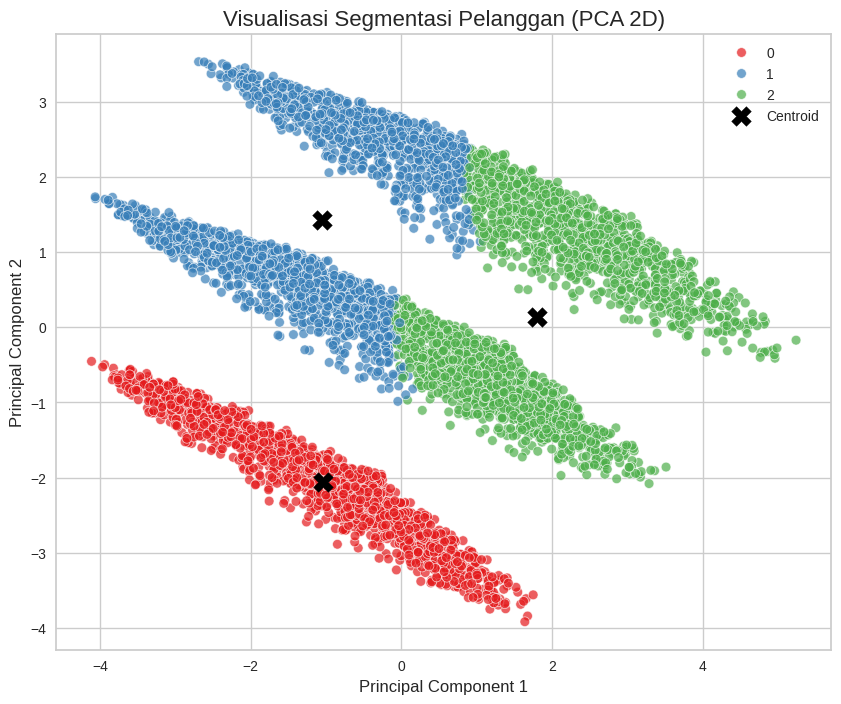

In [ ]:

### MULAI CODE ###

# 1. Inisialisasi PCA untuk 2 komponen
pca = PCA(n_components=2)

# 2. Ambil hanya kolom numerik asli dari df_used untuk PCA (menghindari kolom kategorial seperti 'Nama_Segmen' atau 'Target')
features_for_pca = df_used[numerical_cols]

# Fit dan transform data menggunakan data yang murni numerik
pca_result = pca.fit_transform(features_for_pca)

# 3. Masukkan ke DataFrame baru
df_pca = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2'])

# 4. Tambahkan label cluster dari kmeans_final
df_pca['Cluster'] = kmeans_final.labels_

# 5. Visualisasi
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette=sns.color_palette("Set1", n_colors=3),
    data=df_pca,
    legend="full",
    alpha=0.7
)

# 6. Plot Centroid
centers = pca.transform(kmeans_final.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=1, marker='X', label='Centroid')

### SELESAI CODE ###

plt.title('Visualisasi Segmentasi Pelanggan (PCA 2D)', fontsize=16)
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.legend()
plt.show()

In [ ]:
# 1. Hapus kolom 'Target' lama (termasuk yang duplikat) dan 'Nama_Segmen' agar bersih
columns_to_drop = [col for col in df_used.columns if col in ['Target', 'Nama_Segmen']]
df_used.drop(columns=columns_to_drop, inplace=True, errors='ignore')

# 2. Masukkan kembali label kluster dari kmeans_final yang benar (hanya memiliki kelas 0, 1, dan 2)
df_used['Target'] = kmeans_final.labels_

# 3. Lakukan kembali mapping segmen berdasarkan 3 kluster
nama_cluster = {
    0: 'Active',
    1: 'At Risk',
    2: 'Need Attention'
}
df_used['Nama_Segmen'] = df_used['Target'].map(nama_cluster)

# 4. Tampilkan data untuk memverifikasi hasilnya
display(df_used[['Target', 'Nama_Segmen']].head())
print("Nilai unik pada kolom Target sekarang:", df_used['Target'].unique())

,Target,Nama_Segmen
0,2,Need Attention
4,0,Active
5,0,Active
6,0,Active
8,1,At Risk


Nilai unik pada kolom Target sekarang: [2 0 1]


In [ ]:
df_profile = df_used.copy()
df_profile['Cluster'] = kmeans_final.labels_
agg_summary = df_profile.groupby('Cluster')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T
display(agg_summary.style.set_table_styles([
    {'selector': 'th', 'props': [('border', '1px solid black'), ('text-align', 'center') ]},
    {'selector': 'td', 'props': [('border', '1px solid black'), ('text-align', 'center') ]}
]).format(precision=2))

In [ ]:
df_used.rename(columns={"Cluster": "Target"}, inplace=True)
df_used.head()

,package_total_sessions,package_duration_days,days_since_package_purchase,total_sessions_attended,has_ever_visited,attendance_frequency_7d,missed_session_count_7d,reschedule_frequency_7d,remaining_package_sessions,days_until_package_expiry,days_since_last_visit,reminder_count_7d,reminder_response_count_7d,Target,Nama_Segmen
0,-0.068642,-0.068642,-0.738795,-0.950192,0.0,-1.101131,-0.630437,-0.916147,0.760335,0.634873,1.173337,-0.786757,-0.548839,2,Need Attention
4,-1.364304,-1.364304,-1.432527,-1.272177,0.0,-1.101131,0.933479,1.801966,-0.072415,0.059583,0.399293,0.527106,-0.548839,0,Active
5,-1.364304,-1.364304,-1.259094,-1.272177,0.0,-1.101131,-0.630437,-0.916147,-0.072415,-0.104785,0.786315,-0.786757,-0.548839,0,Active
6,-1.364304,-1.364304,-1.259094,-0.950192,0.0,0.182354,-0.630437,0.442910,-0.349998,-0.104785,-0.955284,-0.786757,-0.548839,0,Active
8,1.227021,1.227021,0.041653,0.659738,0.0,1.465839,-0.630437,0.442910,0.482751,1.127979,-0.568262,-0.786757,-0.548839,1,At Risk


In [ ]:
# Simpan Data

### MULAI CODE ###

df_used.to_csv('data_clustering.csv', index=False)

### SELESAI CODE ###

In [ ]:
# 1. Memuat ulang data asli GymnasiumDataset sebelum di-scale
df_original = pd.read_csv('synthetic_customer_retention.csv')

# 2. Filter data asli agar barisnya sama persis dengan df_used (setelah pembersihan outlier)
df_inverse = df_original.loc[df_used.index].copy()

# 3. Masukkan kolom Target dan Nama_Segmen hasil clustering ke data asli tersebut
df_inverse['Target'] = df_used['Target']
df_inverse['Nama_Segmen'] = df_used['Nama_Segmen']

# Tentukan kolom kategorikal
categorical_cols = ['Nama_Segmen']

### MULAI CODE ###

# Kelompokkan (groupby) 'df_inverse' berdasarkan 'Target' dan hitung agregasi untuk 'numerical_cols'.
agg_summary_num = df_inverse.groupby('Target')[numerical_cols].agg(['mean', 'min', 'max']).round(2).T

# Kelompokkan (groupby) 'df_inverse' berdasarkan 'Target' dan hitung agregasi untuk 'categorical_cols'.
agg_summary_cat = df_inverse.groupby('Target')[categorical_cols].agg(lambda x: x.mode()[0]).round(2).T

### SELESAI CODE ###

# Tampilkan kedua hasil ringkasan
print("=== ANALISIS DESKRIPTIF FITUR NUMERIK (DATA ASLI SEBENARNYA) ===")
display(agg_summary_num)
print("\n=== ANALISIS DESKRIPTIF FITUR KATEGORIKAL (DATA ASLI SEBENARNYA) ===")
display(agg_summary_cat)

=== ANALISIS DESKRIPTIF FITUR NUMERIK (DATA ASLI SEBENARNYA) ===


Target                                0      1      2
package_total_sessions      mean   8.00  13.70  13.88
                            min    8.00  12.00  12.00
                            max    8.00  16.00  16.00
package_duration_days       mean  30.00  51.39  52.04
                            min   30.00  45.00  45.00
                            max   30.00  60.00  60.00
days_since_package_purchase mean  15.96  31.65  21.19
                            min    0.00   8.00   0.00
                            max   29.00  59.00  59.00
total_sessions_attended     mean   3.41   7.99   3.13
                            min    1.00   1.00   1.00
                            max    8.00  12.00  11.00
has_ever_visited            mean   1.00   1.00   1.00
                            min    1.00   1.00   1.00
                            max    1.00   1.00   1.00
attendance_frequency_7d     mean   1.50   2.79   0.82
                            min    0.00   0.00   0.00
                            max    5.00   5.00   5.00
missed_session_count_7d     mean   0.42   0.17   0.61
                            min    0.00   0.00   0.00
                            max    2.00   2.00   2.00
reschedule_frequency_7d     mean   0.64   0.64   0.73
                            min    0.00   0.00   0.00
                            max    2.00   2.00   2.00
remaining_package_sessions  mean   4.59   5.72  10.75
                            min    0.00   0.00   4.00
                            max    7.00  14.00  15.00
days_until_package_expiry   mean  14.04  19.74  30.85
                            min    1.00   1.00   1.00
                            max   30.00  49.00  57.00
days_since_last_visit       mean   4.90   2.51   7.33
                            min    0.00   0.00   0.00
                            max   23.00  22.00  23.00
reminder_count_7d           mean   0.62   0.27   0.90
                            min    0.00   0.00   0.00
                            max    2.00   2.00   2.00
reminder_response_count_7d  mean   0.31   0.16   0.44
                            min    0.00   0.00   0.00
                            max    2.00   2.00   2.00


=== ANALISIS DESKRIPTIF FITUR KATEGORIKAL (DATA ASLI SEBENARNYA) ===


Target,0,1,2
Nama_Segmen,Active,At Risk,Need Attention


In [ ]:
# Periksa kembali data yang telah di-inverse.

### MULAI CODE ###

df_inverse.head()

### SELESAI CODE ###

,customer_id,package_total_sessions,package_duration_days,days_since_package_purchase,total_sessions_attended,has_ever_visited,attendance_frequency_7d,missed_session_count_7d,reschedule_frequency_7d,remaining_package_sessions,days_until_package_expiry,days_since_last_visit,reminder_count_7d,reminder_response_count_7d,Target,Nama_Segmen
0,CUST00001,12,45,15,2,1,0,0,0,10,30,11,0,0,2,Need Attention
4,CUST00005,8,30,7,1,1,0,1,2,7,23,7,1,0,0,Active
5,CUST00006,8,30,9,1,1,0,0,0,7,21,9,0,0,0,Active
6,CUST00007,8,30,9,2,1,2,0,1,6,21,0,0,0,0,Active
8,CUST00009,16,60,24,7,1,4,0,1,9,36,2,0,0,1,At Risk


In [ ]:
# Simpan Data Inverse

### MULAI CODE ###

df_inverse.to_csv('data_clustering_inverse.csv', index=False)

### SELESAI CODE ###